# Model Training: Demand Tier Classification 

Trains a **LOW / MEDIUM / HIGH** demand tier classifier for morning and afternoon shifts.

- **Three candidates**: Random Forest, XGBoost, LightGBM
- **Three-way temporal split**: 70% train / 15% validation / 15% test (no random shuffling)
- **Validation set** monitors overfitting; **test set** used only for final evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
import lightgbm as lgb
import joblib
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
DATA = Path("../data_prep/outputs")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("../thesis/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA / "training_data.csv", parse_dates=["date"])
print(f"{len(df):,} rows  |  {df['date'].nunique()} unique dates")
print(f"Date range: {df['date'].min().date()} → {df['date'].max().date()}")
print(f"Tier distribution:\n{df.groupby(['shift', 'tier']).size().unstack(fill_value=0)}")

1,676 rows  |  840 unique dates
Date range: 2023-12-04 → 2026-04-12
Tier distribution:
tier       high  low  medium
shift                       
afternoon   385  266     189
morning     332  163     341


## 1. Feature Preparation

In [2]:
FEATURE_COLS = ["occupancy_pct", "day_of_week", "is_weekend", "is_special_day",
                "temp_mean", "temp_max"]

# One-hot encode season
season_dummies = pd.get_dummies(df["season"], prefix="season", drop_first=True)
df = pd.concat([df, season_dummies], axis=1)
season_cols = list(season_dummies.columns)

all_features = FEATURE_COLS + season_cols
print(f"Feature columns ({len(all_features)}): {all_features}")

# Encode tier labels: high=0, low=1, medium=2 (alphabetical)
le = LabelEncoder()
df["tier_encoded"] = le.fit_transform(df["tier"])
print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

Feature columns (9): ['occupancy_pct', 'day_of_week', 'is_weekend', 'is_special_day', 'temp_mean', 'temp_max', 'season_Spring', 'season_Summer', 'season_Winter']
Label mapping: {'high': np.int64(0), 'low': np.int64(1), 'medium': np.int64(2)}


## 2. Three-Way Temporal Split (70 / 15 / 15)

In [ ]:
sorted_dates = sorted(df["date"].unique())
n_dates = len(sorted_dates)
train_end = sorted_dates[int(n_dates * 0.70) - 1]
val_end   = sorted_dates[int(n_dates * 0.85) - 1]

print(f"Total dates: {n_dates}")
print(f"Train:  start → {train_end.date()}  ({int(n_dates*0.70)} dates)")
print(f"Val:    {sorted_dates[int(n_dates*0.70)].date()} → {val_end.date()}  ({int(n_dates*0.15)} dates)")
print(f"Test:   {sorted_dates[int(n_dates*0.85)].date()} → {sorted_dates[-1].date()}  ({n_dates - int(n_dates*0.85)} dates)")

train_mask = df["date"] <= train_end
val_mask   = (df["date"] > train_end) & (df["date"] <= val_end)
test_mask  = df["date"] > val_end

splits = {}
for shift_name in ["morning", "afternoon"]:
    shift = df[df["shift"] == shift_name]
    splits[shift_name] = {
        "y_train": shift.loc[train_mask & (df["shift"] == shift_name), "tier_encoded"],
        "X_val":   shift.loc[val_mask & (df["shift"] == shift_name), all_features],
        "y_val":   shift.loc[val_mask & (df["shift"] == shift_name), "tier_encoded"],
        "X_test":  shift.loc[test_mask & (df["shift"] == shift_name), all_features],
        "y_test":  shift.loc[test_mask & (df["shift"] == shift_name), "tier_encoded"],
    }
    print(f"\n{shift_name}: train={len(splits[shift_name]['X_train'])}"
          f"  val={len(splits[shift_name]['X_val'])}"
          f"  test={len(splits[shift_name]['X_test'])}")

Total dates: 840
Train:  start → 2025-07-27  (588 dates)
Val:    2025-07-28 → 2025-11-30  (126 dates)
Test:   2025-12-01 → 2026-04-12  (126 dates)

morning: train=588  val=126  test=122

afternoon: train=588  val=126  test=126


## 3. Train Models

Three candidates per shift: Random Forest, XGBoost, LightGBM.  
XGBoost and LightGBM use early stopping on the validation set.

In [ ]:
def train_all_models(data):
    X_tr, y_tr = data["X_train"], data["y_train"]
    X_val, y_val = data["X_val"], data["y_val"]
    models = {}
    histories = {}

    # --- Random Forest ---
    randomforest = RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=5,
        random_state=42, n_jobs=-1
    )
    randomforest.fit(X_tr, y_tr)
    models["Random Forest"] = randomforest

    # Training curve for Random Forest(incremental OOB)
    randomforest_train_scores, randomforest_val_scores = [], []
    for n in range(10, 301, 10):
        randomforest_temp = RandomForestClassifier(
            n_estimators=n, max_depth=8, min_samples_leaf=5,
            random_state=42, n_jobs=-1
        )
        randomforest_temp.fit(X_tr, y_tr)
        randomforest_train_scores.append(randomforest_temp.score(X_tr, y_tr))
        randomforest_val_scores.append(randomforest_temp.score(X_val, y_val))
    histories["Random Forest"] = {
        "train": randomforest_train_scores, "val": randomforest_val_scores,
        "x": list(range(10, 301, 10)), "xlabel": "Number of Trees"
    }

    # --- XGBoost ---
    xgb_model = xgb.XGBClassifier(
        n_estimators=500, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="mlogloss", random_state=42,
        early_stopping_rounds=30,
    )
    xgb_model.fit(
        X_tr, y_tr,
        eval_set=[(X_tr, y_tr), (X_val, y_val)],
        verbose=False
    )
    models["XGBoost"] = xgb_model

    xgb_results = xgb_model.evals_result()
    n_rounds = len(xgb_results["validation_0"]["mlogloss"])
    
    # Convert logloss to accuracy approximation via eval on subsets
    xgb_train_acc, xgb_val_acc = [], []
    for i in range(1, n_rounds + 1, max(1, n_rounds // 30)):
        xgb_temp = xgb.XGBClassifier(
            n_estimators=i, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=42,
        )
        xgb_temp.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        xgb_train_acc.append(xgb_temp.score(X_tr, y_tr))
        xgb_val_acc.append(xgb_temp.score(X_val, y_val))
    histories["XGBoost"] = {
        "train": xgb_train_acc, "val": xgb_val_acc,
        "x": list(range(1, n_rounds + 1, max(1, n_rounds // 30))),
        "xlabel": "Boosting Rounds",
        "best_round": xgb_model.best_iteration
    }

    # --- LightGBM ---
    lgb_model = lgb.LGBMClassifier(
        n_estimators=500, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42, verbose=-1,
    )
    lgb_model.fit(
        X_tr, y_tr,
        eval_set=[(X_tr, y_tr), (X_val, y_val)],
        eval_metric="multi_logloss",
        callbacks=[
            lgb.early_stopping(30, verbose=False),
            lgb.log_evaluation(period=0),
        ]
    )
    models["LightGBM"] = lgb_model

    n_lgb = lgb_model.best_iteration_ or lgb_model.n_estimators
    lgb_train_acc, lgb_val_acc = [], []
    for i in range(10, n_lgb + 1, max(1, n_lgb // 30)):
        lgb_temp = lgb.LGBMClassifier(
            n_estimators=i, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
        )
        lgb_temp.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
                     eval_metric="multi_logloss",
                     callbacks=[lgb.log_evaluation(period=0)])
        lgb_train_acc.append(lgb_temp.score(X_tr, y_tr))
        lgb_val_acc.append(lgb_temp.score(X_val, y_val))
    histories["LightGBM"] = {
        "train": lgb_train_acc, "val": lgb_val_acc,
        "x": list(range(10, n_lgb + 1, max(1, n_lgb // 30))),
        "xlabel": "Boosting Rounds",
        "best_round": lgb_model.best_iteration_
    }

    return models, histories


results = {}
for shift_name in ["morning", "afternoon"]:
    print(f"\n{'='*50}")
    print(f"Training {shift_name.upper()} models...")
    print(f"{'='*50}")
    models, histories = train_all_models(splits[shift_name])
    results[shift_name] = {"models": models, "histories": histories}

    for name, model in models.items():
        val_acc = accuracy_score(splits[shift_name]["y_val"], model.predict(splits[shift_name]["X_val"]))
        print(f"  {name:15s}  val accuracy = {val_acc:.3f}")

print("\nAll models trained.")


Training MORNING models...
  Random Forest    val accuracy = 0.984
  XGBoost          val accuracy = 1.000
  LightGBM         val accuracy = 1.000

Training AFTERNOON models...
  Random Forest    val accuracy = 0.849
  XGBoost          val accuracy = 0.937
  LightGBM         val accuracy = 0.921

All models trained.


## 4. Overfitting Diagnostic — Training vs Validation Curves

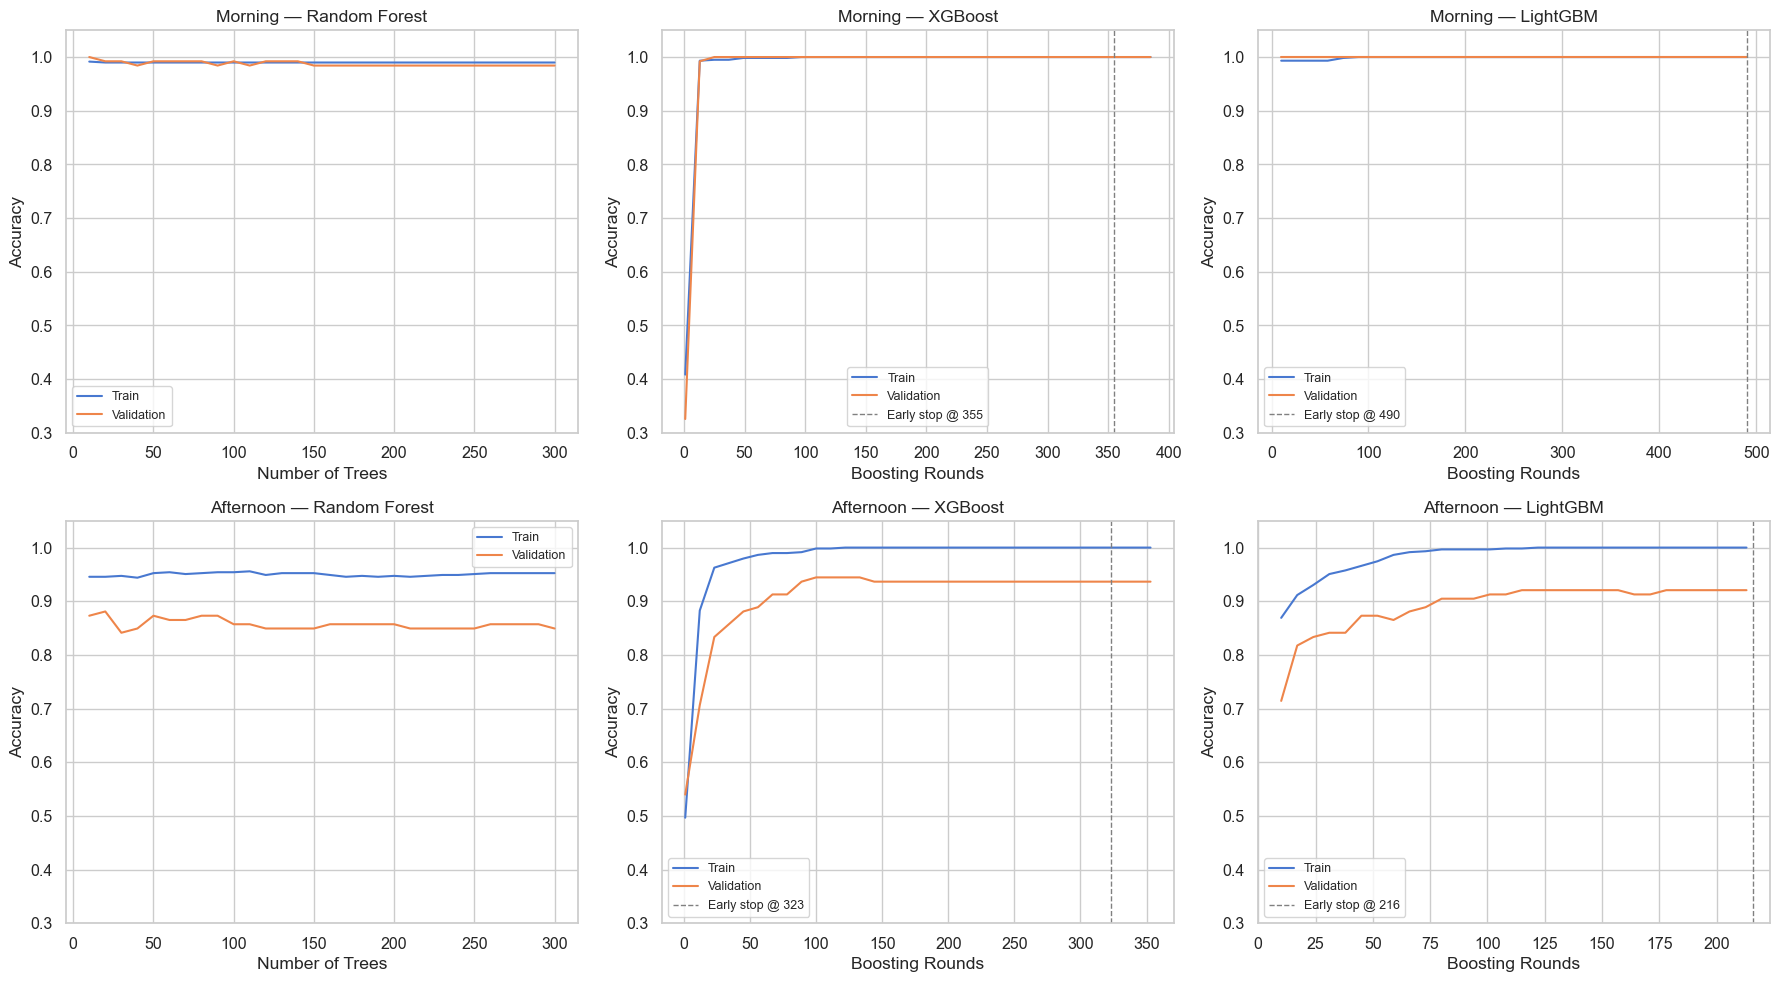

Saved model_learning_curves.png


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for row, shift_name in enumerate(["morning", "afternoon"]):
    for col, model_name in enumerate(["Random Forest", "XGBoost", "LightGBM"]):
        ax = axes[row, col]
        h = results[shift_name]["histories"][model_name]
        ax.plot(h["x"][:len(h["train"])], h["train"], label="Train", linewidth=1.5)
        ax.plot(h["x"][:len(h["val"])], h["val"], label="Validation", linewidth=1.5)
        if "best_round" in h and h["best_round"]:
            ax.axvline(h["best_round"], color="gray", ls="--", lw=1,
                       label=f"Early stop @ {h['best_round']}")
        ax.set_xlabel(h["xlabel"])
        ax.set_ylabel("Accuracy")
        ax.set_title(f"{shift_name.title()} — {model_name}")
        ax.legend(fontsize=9)
        ax.set_ylim(0.3, 1.05)

plt.tight_layout()
fig.savefig(FIG_DIR / "model_learning_curves.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved model_learning_curves.png")

## 5. Final Evaluation on Test Set

In [6]:
summary_rows = []

for shift_name in ["morning", "afternoon"]:
    X_test = splits[shift_name]["X_test"]
    y_test = splits[shift_name]["y_test"]

    print(f"\n{'='*60}")
    print(f"{shift_name.upper()} SHIFT — TEST SET EVALUATION")
    print(f"{'='*60}")

    for name, model in results[shift_name]["models"].items():
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        print(f"\n--- {name} (accuracy: {acc:.3f}) ---")
        print(classification_report(y_test, y_pred, target_names=le.classes_))

        summary_rows.append({
            "shift": shift_name, "model": name, "accuracy": round(acc, 3)
        })

summary = pd.DataFrame(summary_rows)
print("\n=== SUMMARY ===")
print(summary.pivot(index="model", columns="shift", values="accuracy"))


MORNING SHIFT — TEST SET EVALUATION

--- Random Forest (accuracy: 0.984) ---
              precision    recall  f1-score   support

        high       1.00      0.94      0.97        34
         low       1.00      1.00      1.00        28
      medium       0.97      1.00      0.98        60

    accuracy                           0.98       122
   macro avg       0.99      0.98      0.98       122
weighted avg       0.98      0.98      0.98       122


--- XGBoost (accuracy: 0.984) ---
              precision    recall  f1-score   support

        high       1.00      0.94      0.97        34
         low       1.00      1.00      1.00        28
      medium       0.97      1.00      0.98        60

    accuracy                           0.98       122
   macro avg       0.99      0.98      0.98       122
weighted avg       0.98      0.98      0.98       122


--- LightGBM (accuracy: 0.984) ---
              precision    recall  f1-score   support

        high       1.00      0.94 

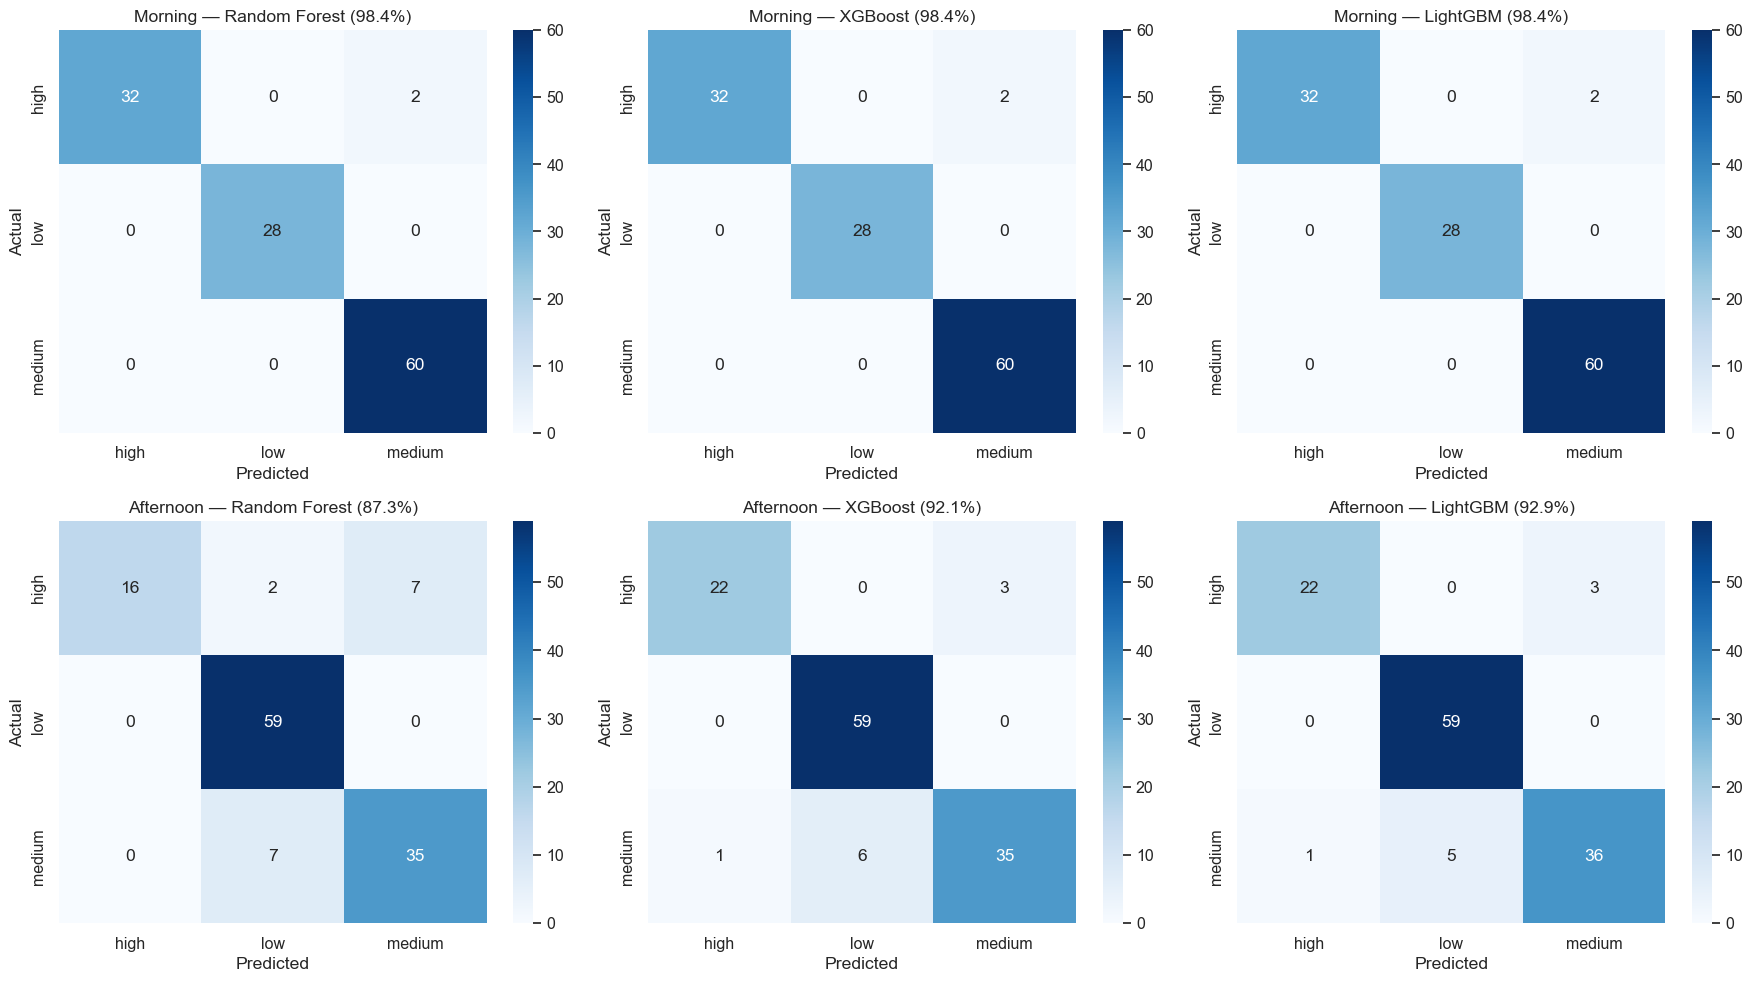

Saved model_confusion_matrices.png


In [7]:
# Confusion matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for row, shift_name in enumerate(["morning", "afternoon"]):
    X_test = splits[shift_name]["X_test"]
    y_test = splits[shift_name]["y_test"]

    for col, (name, model) in enumerate(results[shift_name]["models"].items()):
        ax = axes[row, col]
        y_pred = model.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                    xticklabels=le.classes_, yticklabels=le.classes_)
        acc = accuracy_score(y_test, y_pred)
        ax.set_title(f"{shift_name.title()} — {name} ({acc:.1%})")
        ax.set_ylabel("Actual")
        ax.set_xlabel("Predicted")

plt.tight_layout()
fig.savefig(FIG_DIR / "model_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved model_confusion_matrices.png")

## 6. Feature Importance — Best Model

morning: Best model = Random Forest (test accuracy = 0.984)
afternoon: Best model = LightGBM (test accuracy = 0.929)


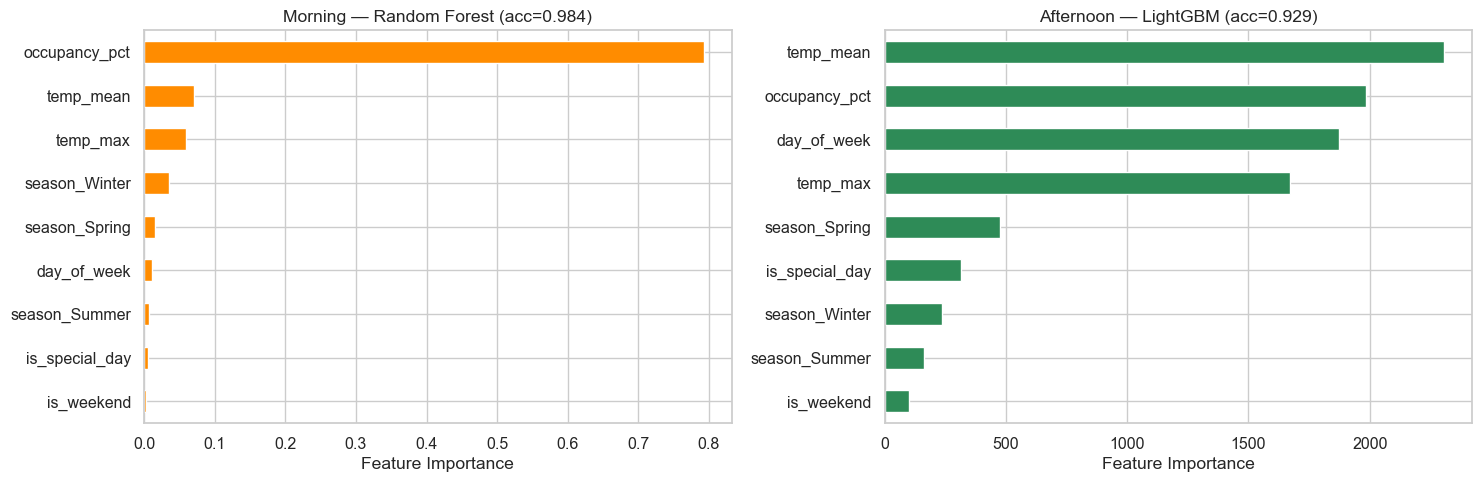

Saved model_feature_importance.png


In [8]:
# Select best model per shift
best_models = {}
for shift_name in ["morning", "afternoon"]:
    X_test = splits[shift_name]["X_test"]
    y_test = splits[shift_name]["y_test"]
    best_name, best_acc = None, -1
    for name, model in results[shift_name]["models"].items():
        acc = accuracy_score(y_test, model.predict(X_test))
        if acc > best_acc:
            best_name, best_acc = name, acc
    best_models[shift_name] = {"name": best_name, "model": results[shift_name]["models"][best_name], "acc": best_acc}
    print(f"{shift_name}: Best model = {best_name} (test accuracy = {best_acc:.3f})")

# Feature importance for best models
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (shift_name, info) in zip(axes, best_models.items()):
    model = info["model"]
    imp = pd.Series(model.feature_importances_, index=all_features).sort_values(ascending=True)
    color = "darkorange" if shift_name == "morning" else "seagreen"
    imp.plot(kind="barh", ax=ax, color=color)
    ax.set_xlabel("Feature Importance")
    ax.set_title(f"{shift_name.title()} — {info['name']} (acc={info['acc']:.3f})")

plt.tight_layout()
fig.savefig(FIG_DIR / "model_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved model_feature_importance.png")

## 7. Export Best Models

In [9]:
for shift_name, info in best_models.items():
    model_path = MODEL_DIR / f"tier_model_{shift_name}.pkl"
    joblib.dump(info["model"], model_path)
    print(f"Saved {info['name']} → {model_path}")

# Also save the label encoder and feature list for integration
joblib.dump(le, MODEL_DIR / "tier_label_encoder.pkl")
joblib.dump(all_features, MODEL_DIR / "tier_feature_cols.pkl")
print(f"\nLabel encoder and feature list saved to {MODEL_DIR}")
print(f"\nLabel mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")
print(f"Features: {all_features}")

Saved Random Forest → ../models/tier_model_morning.pkl
Saved LightGBM → ../models/tier_model_afternoon.pkl

Label encoder and feature list saved to ../models

Label mapping: {'high': np.int64(0), 'low': np.int64(1), 'medium': np.int64(2)}
Features: ['occupancy_pct', 'day_of_week', 'is_weekend', 'is_special_day', 'temp_mean', 'temp_max', 'season_Spring', 'season_Summer', 'season_Winter']


## 8. Summary for Thesis

In [10]:
print("=" * 60)
print("THESIS SUMMARY")
print("=" * 60)
print(f"\nDataset: {len(df):,} rows, {df['date'].nunique()} dates")
print(f"Split: 70% train / 15% val / 15% test (temporal, no shuffle)")
print(f"Train: → {train_end.date()}  |  Val: → {val_end.date()}  |  Test: → {sorted_dates[-1].date()}")
print(f"\nFeatures ({len(all_features)}): {all_features}")
print(f"\n{'Model':<20} {'Morning Acc':>12} {'Afternoon Acc':>14}")
print("-" * 48)
for model_name in ["Random Forest", "XGBoost", "LightGBM"]:
    m_acc = accuracy_score(
        splits["morning"]["y_test"],
        results["morning"]["models"][model_name].predict(splits["morning"]["X_test"])
    )
    a_acc = accuracy_score(
        splits["afternoon"]["y_test"],
        results["afternoon"]["models"][model_name].predict(splits["afternoon"]["X_test"])
    )
    marker = " ★" if model_name == best_models["morning"]["name"] or model_name == best_models["afternoon"]["name"] else ""
    print(f"{model_name:<20} {m_acc:>11.1%} {a_acc:>13.1%}{marker}")

print(f"\nBest morning:   {best_models['morning']['name']} ({best_models['morning']['acc']:.1%})")
print(f"Best afternoon: {best_models['afternoon']['name']} ({best_models['afternoon']['acc']:.1%})")

THESIS SUMMARY

Dataset: 1,676 rows, 840 dates
Split: 70% train / 15% val / 15% test (temporal, no shuffle)
Train: → 2025-07-27  |  Val: → 2025-11-30  |  Test: → 2026-04-12

Features (9): ['occupancy_pct', 'day_of_week', 'is_weekend', 'is_special_day', 'temp_mean', 'temp_max', 'season_Spring', 'season_Summer', 'season_Winter']

Model                 Morning Acc  Afternoon Acc
------------------------------------------------
Random Forest              98.4%         87.3% ★
XGBoost                    98.4%         92.1%
LightGBM                   98.4%         92.9% ★

Best morning:   Random Forest (98.4%)
Best afternoon: LightGBM (92.9%)


## 9. Permutation Test — Validating Signal Isn't Spurious

Refit each saved model 100× on randomly shuffled training labels. If real accuracy >> permuted distribution, the features contain genuine signal. A p-value is computed as the fraction of permuted runs that matched or beat real accuracy.

In [ ]:
N_PERMUTATIONS = 100
rng = np.random.default_rng(42)

model_constructors = {
    "morning": lambda: RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
    "afternoon": lambda: lgb.LGBMClassifier(
        n_estimators=500, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
perm_results = {}

for ax, shift_name in zip(axes, ["morning", "afternoon"]):
    X_tr = splits[shift_name]["X_train"]
    y_tr = splits[shift_name]["y_train"].values
    X_test = splits[shift_name]["X_test"]
    y_test = splits[shift_name]["y_test"]

    real_acc = best_models[shift_name]["acc"]

    perm_accs = []
    for _ in range(N_PERMUTATIONS):
        y_shuffled = rng.permutation(y_tr)
        m = model_constructors[shift_name]()
        m.fit(X_tr, y_shuffled)
        perm_accs.append(accuracy_score(y_test, m.predict(X_test)))

    perm_accs = np.array(perm_accs)
    p_value = (perm_accs >= real_acc).mean()
    perm_results[shift_name] = {"perm_accs": perm_accs, "p_value": p_value}

    ax.hist(perm_accs, bins=20, color="steelblue", alpha=0.75, edgecolor="white",
            label=f"Permuted (n={N_PERMUTATIONS})")
    ax.axvline(real_acc, color="crimson", linewidth=2, label=f"Real accuracy ({real_acc:.3f})")
    ax.axvline(1 / 3, color="gray", linewidth=1, linestyle="--", label="Chance (0.333)")
    ax.set_xlabel("Test Accuracy")
    ax.set_ylabel("Count")
    ax.set_title(f"{shift_name.title()} — {best_models[shift_name]['name']}\np = {p_value:.4f}")
    ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(FIG_DIR / "permutation_test.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved permutation_test.png")

print("\n=== PERMUTATION TEST RESULTS ===")
for shift_name in ["morning", "afternoon"]:
    pr = perm_results[shift_name]
    print(f"\n{shift_name.title()} — {best_models[shift_name]['name']}")
    print(f"  Real test accuracy : {best_models[shift_name]['acc']:.4f}")
    print(f"  Permuted mean ± std: {pr['perm_accs'].mean():.4f} ± {pr['perm_accs'].std():.4f}")
    print(f"  p-value            : {pr['p_value']:.4f}  {'✓ signal confirmed' if pr['p_value'] < 0.05 else '✗ cannot confirm signal'}")